# Logistic Regression: Fan Fault Detection (ESP32 + MPU6050)

**Aaron Arnold** · TinyML model comparison, Presentation 2 · experiment recorded November 19, 2026

*Personal record of the final experiment. The outputs below are saved from a full run, so the notebook can be read without re-running it.*

### Final results at a glance

| | Result |
|---|---|
| Normal vs. fault, shared split (test = last session of each condition) | precision, recall, F1 = **1.000**, false alarms 0 |
| Normal vs. fault, 5 session-level rounds | F1 **0.993 ± 0.016**, false alarms 0.3% |
| Held-out blade rub (never trained on) | **100%** flagged (83% labelled loose mount, 17% blocked airflow) |
| Which fault (4 classes) | macro F1 **0.983** |
| Fan speed alone (sanity check) | F1 0.667: no RPM shortcut |
| On the ESP32 | 112 B model, 10–18 µs inference, 42.8 ms features, 531/531 windows match Python |
| Live tests | alert 3.1 s after a fault appears; see Section 11 and the lab log (Section 12) |

### What this notebook does

1. Loads the 25 one-minute sessions in `../data/` (5 per condition, ±8 g, 1 kHz, fan at ~1,690 RPM).
2. Extracts the team's **shared features** (`features.py`, copied below): 1-s windows of the acceleration magnitude → RMS, peak, std, kurtosis, crest factor and 4 FFT band energies.
3. Trains and tests normal vs. fault on the **shared split**, repeats it over 5 rounds, scores which fault it is, and tests the **held-out blade rub**.
4. Exports the model to `../model/logreg_model.h` for the ESP32 and checks the C-style math matches scikit-learn.
5. Records the ESP32 verification, the live tests and a lab log of the experiment.

Folder layout: this notebook lives in `fan_fault_experiment/notebook/`; run it from there.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             accuracy_score, confusion_matrix, roc_curve)

ROOT         = Path("..")                 # the fan_fault_experiment folder
DATA_DIR     = ROOT / "data"
MODEL_DIR    = ROOT / "model"
RESULTS_DIR  = ROOT / "results"
TRAIN_LABELS = ["normal", "imbalance", "loose_mount", "blocked_airflow"]
HELDOUT      = "heldout"

# Chart styling (blue = single-series color; sequential blues for confusion matrices)
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10,
})

## 1. Shared feature extraction (`features.py`)

This cell is the team's `features.py` (minus its `__main__` block), so this notebook's features match every other model's.

**One change:** `SCALE_MS2` is `9.80665 / 4096` because the logger now records at **±8 g** (4096 counts per g). The original `features.py` uses `9.80665 / 16384` (±2 g); update it the same way so all models agree. Section 2 stops with an error if any recording in `data/` was made at a different range.

**Note on the bands:** `FREQ_BANDS` was chosen for the old ~720-950 RPM fan speed (12-16 Hz). At the current ~1,690 RPM the spin frequency is ~28 Hz, so imbalance now lands in `band_25_75hz`, not `band_5_25hz`. The code still works; only the comment in `features.py` is out of date.

In [2]:
import glob
import os
import numpy as np
import pandas as pd
from scipy.stats import kurtosis

# Pipeline parameters (1kHz sampling, 1s windows, +/-8g raw counts to m/s^2)
FS = 1000.0
WINDOW_SIZE = 1000
COUNTS_PER_G = 4096.0                # +/-8 g (was 16384 for +/-2 g)
SCALE_MS2 = 9.80665 / COUNTS_PER_G

# FFT frequency bands based on ~720-950 RPM fan speed (12-16 Hz) up to 500 Hz Nyquist
FREQ_BANDS = [
    (5, 25),     # fundamental rotation / imbalance
    (25, 75),    # harmonics / loose mount rattle
    (75, 200),   # blade-pass / airflow turbulence
    (200, 500),  # high-freq friction / impacts
]

FEATURE_NAMES = [
    "rms",
    "peak",
    "std",
    "kurtosis",
    "crest_factor",
    "band_5_25hz",
    "band_25_75hz",
    "band_75_200hz",
    "band_200_500hz",
]

CLASS_MAP = {
    "normal": 0,
    "imbalance": 1,
    "loose_mount": 2,
    "blocked_airflow": 3,
}


def extract_window_features(win_ms2):
    # Time-domain stats
    rms = float(np.sqrt(np.mean(win_ms2 ** 2)))
    peak = float(np.max(np.abs(win_ms2)))
    std = float(np.std(win_ms2))
    kurt = float(kurtosis(win_ms2, fisher=True))
    crest = float(peak / rms) if rms > 0 else 0.0

    # AC-coupled FFT band energies
    win_ac = win_ms2 - np.mean(win_ms2)
    fft_mag = np.abs(np.fft.rfft(win_ac)) * 2.0 / len(win_ac)
    freqs = np.fft.rfftfreq(len(win_ac), d=1.0 / FS)

    band_energies = []
    for low_hz, high_hz in FREQ_BANDS:
        mask = (freqs >= low_hz) & (freqs < high_hz)
        band_energies.append(float(np.mean(fft_mag[mask] ** 2)))

    return [rms, peak, std, kurt, crest] + band_energies


def load_dataset(data_dir="data"):
    X_train, y_train = [], []
    X_test, y_test = [], []
    X_heldout = []

    for label_name, class_id in CLASS_MAP.items():
        files = sorted(glob.glob(os.path.join(data_dir, f"{label_name}_*.csv")))
        if not files:
            raise FileNotFoundError(f"Missing CSV files for {label_name} in {data_dir}/")

        for i, fp in enumerate(files):
            df = pd.read_csv(fp).dropna()
            ax = df["ax"].values * SCALE_MS2
            ay = df["ay"].values * SCALE_MS2
            az = df["az"].values * SCALE_MS2
            mag = np.sqrt(ax**2 + ay**2 + az**2)

            # Hold out last recording session per class to prevent window leakage
            is_test = (i == len(files) - 1)

            for w in range(len(mag) // WINDOW_SIZE):
                win = mag[w * WINDOW_SIZE : (w + 1) * WINDOW_SIZE]
                feats = extract_window_features(win)
                if is_test:
                    X_test.append(feats)
                    y_test.append(class_id)
                else:
                    X_train.append(feats)
                    y_train.append(class_id)

    # Separate unseen held-out fault ("wire poking fan") for OOD testing
    for fp in sorted(glob.glob(os.path.join(data_dir, "heldout_*.csv"))):
        df = pd.read_csv(fp).dropna()
        ax = df["ax"].values * SCALE_MS2
        ay = df["ay"].values * SCALE_MS2
        az = df["az"].values * SCALE_MS2
        mag = np.sqrt(ax**2 + ay**2 + az**2)

        for w in range(len(mag) // WINDOW_SIZE):
            win = mag[w * WINDOW_SIZE : (w + 1) * WINDOW_SIZE]
            X_heldout.append(extract_window_features(win))

    return (
        np.array(X_train),
        np.array(y_train),
        np.array(X_test),
        np.array(y_test),
        np.array(X_heldout),
    )

In [3]:
X_tr_shared, y_tr_shared, X_te_shared, y_te_shared, X_ood_shared = load_dataset(str(DATA_DIR))
print(f"Features ({len(FEATURE_NAMES)}): {FEATURE_NAMES}")
print(f"Train: {X_tr_shared.shape} | Class counts: {np.bincount(y_tr_shared)}")
print(f"Test:  {X_te_shared.shape} | Class counts: {np.bincount(y_te_shared)}")
print(f"Held-out: {X_ood_shared.shape}")

Features (9): ['rms', 'peak', 'std', 'kurtosis', 'crest_factor', 'band_5_25hz', 'band_25_75hz', 'band_75_200hz', 'band_200_500hz']
Train: (945, 9) | Class counts: [237 236 236 236]
Test:  (236, 9) | Class counts: [59 59 59 59]
Held-out: (295, 9)


## 2. Session info and a per-window table

`load_dataset()` doesn't say which session each window came from, and the robustness check (section 4) needs that. So the cell below builds the same windows with the same `extract_window_features()`, tagged with their session, and then **checks that the result is identical to `load_dataset()`'s output**.

It also checks every session's `.json`: each must be recorded at the same range as `COUNTS_PER_G` (recordings from before the range change have no `counts_per_g` field and count as ±2 g), and it warns about sessions with clipped readings.

In [4]:
sess_rows, win_rows = [], []
wrong_range, clipped_sessions = [], []
for label in TRAIN_LABELS + [HELDOUT]:
    for csv_path in sorted(DATA_DIR.glob(f"{label}_*.csv")):
        meta = json.loads(csv_path.with_suffix(".json").read_text())
        if meta.get("counts_per_g", 16384) != COUNTS_PER_G:
            wrong_range.append(f"{csv_path.name} ({meta.get('accel_range')})")
        if meta.get("clipped_values"):
            clipped_sessions.append(f"{csv_path.name} ({meta['clipped_values']} clipped)")
if wrong_range:
    raise ValueError(f"These recordings are not at {COUNTS_PER_G:.0f} counts per g; move them out of "
                     f"{DATA_DIR}/ or re-record them:\n  " + "\n  ".join(wrong_range))
if clipped_sessions:
    print("Warning: these sessions have clipped readings (consider re-recording):\n  "
          + "\n  ".join(clipped_sessions))

for label in TRAIN_LABELS + [HELDOUT]:
    for i, csv_path in enumerate(sorted(DATA_DIR.glob(f"{label}_*.csv"))):
        meta = json.loads(csv_path.with_suffix(".json").read_text())
        sess_rows.append({"session": csv_path.stem, "label": label, "idx": i,
                          "started": meta["started"], "rpm": meta["mean_fan_rpm"],
                          "gaps": meta["gaps_over_1_5ms"], "notes": meta["notes"]})
        df = pd.read_csv(csv_path).dropna()
        mag = np.sqrt((df["ax"].values * SCALE_MS2) ** 2 + (df["ay"].values * SCALE_MS2) ** 2
                      + (df["az"].values * SCALE_MS2) ** 2)
        for w in range(len(mag) // WINDOW_SIZE):
            feats = extract_window_features(mag[w * WINDOW_SIZE:(w + 1) * WINDOW_SIZE])
            win_rows.append(dict(zip(FEATURE_NAMES, feats), session=csv_path.stem, label=label, idx=i))

sess_df = pd.DataFrame(sess_rows)
feat_df = pd.DataFrame(win_rows)

# Check: same windows and features as the shared load_dataset()
tr = feat_df[feat_df.label.isin(TRAIN_LABELS) & (feat_df.idx < 4)]
te = feat_df[feat_df.label.isin(TRAIN_LABELS) & (feat_df.idx == 4)]
ho = feat_df[feat_df.label == HELDOUT]
assert np.allclose(tr[FEATURE_NAMES].to_numpy(), X_tr_shared)
assert np.allclose(te[FEATURE_NAMES].to_numpy(), X_te_shared)
assert np.allclose(ho[FEATURE_NAMES].to_numpy(), X_ood_shared)
assert (tr.label.map(CLASS_MAP).to_numpy() == y_tr_shared).all()
print("Per-window table matches load_dataset() exactly.")

sess_df.groupby("label").agg(sessions=("session", "count"), mean_rpm=("rpm", "mean"),
                             total_gaps=("gaps", "sum")).round(1)

Per-window table matches load_dataset() exactly.


,sessions,mean_rpm,total_gaps
label,,,
blocked_airflow,5,1686.0,52
heldout,5,1687.0,22
imbalance,5,1694.0,45
loose_mount,5,1687.0,37
normal,5,1688.4,48


> **Note on fan speed:** an earlier dataset had normal sessions at ~950 RPM and every fault at ~690-800 RPM because of a faulty ground, so a model could learn "slower fan" instead of the fault. After fixing the ground, all sessions run at the same fan duty (204/255) and about 1,690 RPM. Section 6 checks that fan speed *alone* no longer separates the classes.

### FFT spectrum of one session per condition

The spectrum below uses one session per condition (set `SPECTRUM_SESSION` to pick a different one, 1-5). It uses the same signal as `features.py`: the acceleration magnitude in m/s², split into 1-second windows with each window's mean removed. The FFT amplitude is averaged over all windows in the session.

- **Orange dashed line:** the fan's 1x spin frequency (RPM / 60) from the session's `.json` file. Imbalance should show up most strongly here.
- **Gray lines:** the edges of the 4 `FREQ_BANDS` used as features.
- The MPU6050's low-pass filter (~184 Hz bandwidth) weakens content above that, so read the 200-500 Hz band with care.

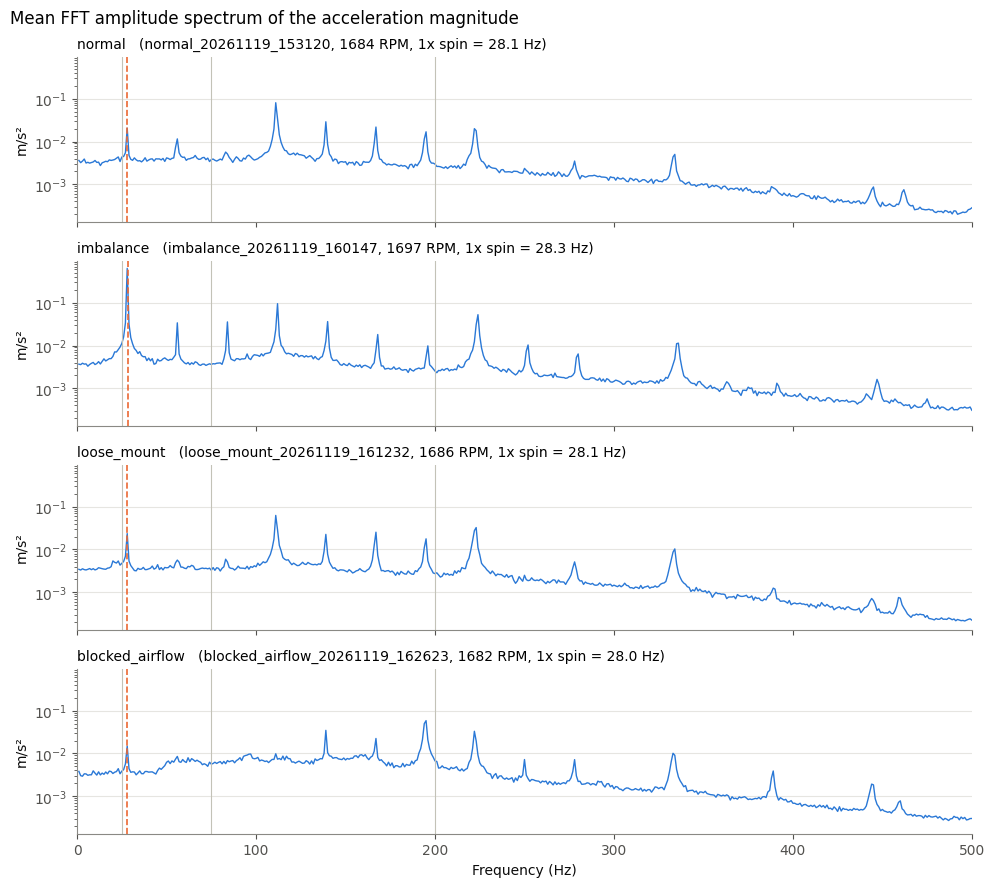

In [5]:
SPECTRUM_SESSION = 2   # which session of each condition to plot (1-5); normal session 1 has a bump at 50 s

freqs = np.fft.rfftfreq(WINDOW_SIZE, d=1.0 / FS)
fig, axes = plt.subplots(len(TRAIN_LABELS), 1, figsize=(10, 9), sharex=True, sharey=True)
for ax, label in zip(axes, TRAIN_LABELS):
    row = sess_df[(sess_df.label == label) & (sess_df.idx == SPECTRUM_SESSION - 1)].iloc[0]
    df = pd.read_csv(DATA_DIR / f"{row.session}.csv").dropna()
    mag = np.sqrt((df["ax"].values * SCALE_MS2) ** 2 + (df["ay"].values * SCALE_MS2) ** 2
                  + (df["az"].values * SCALE_MS2) ** 2)
    n_win = len(mag) // WINDOW_SIZE
    wins = mag[:n_win * WINDOW_SIZE].reshape(n_win, WINDOW_SIZE)
    wins = wins - wins.mean(axis=1, keepdims=True)
    amp = (np.abs(np.fft.rfft(wins, axis=1)) * 2.0 / WINDOW_SIZE).mean(axis=0)

    ax.semilogy(freqs[1:], amp[1:], color=BLUE, lw=1)
    for lo, _ in FREQ_BANDS[1:]:
        ax.axvline(lo, color="#c3c2b7", lw=0.8)
    if pd.notna(row.rpm):
        spin_hz = row.rpm / 60
        ax.axvline(spin_hz, color=ORANGE, ls="--", lw=1.2)
        rpm_txt = f"{row.rpm:.0f} RPM, 1x spin = {spin_hz:.1f} Hz"
    else:
        rpm_txt = "no RPM"
    ax.set_title(f"{label}   ({row.session}, {rpm_txt})", loc="left", fontsize=10)
    ax.set_ylabel("m/s²")
    ax.grid(axis="x", visible=False)

axes[-1].set_xlim(0, 500)
axes[-1].set_xlabel("Frequency (Hz)")
fig.suptitle("Mean FFT amplitude spectrum of the acceleration magnitude", x=0.01, ha="left")
plt.tight_layout(); plt.show()

## 3. Main result: normal vs. fault on the shared split

- **Train:** sessions 1-4 of each condition. **Test:** session 5 (the last one), exactly as in `load_dataset()`.
- Features are standardized (`StandardScaler`), which the ESP32 will repeat with the exported mean/scale.
- The regularization strength `C` is tuned with session-grouped CV **on the training sessions only**.
- `class_weight="balanced"` because there are 3x more fault windows than normal windows.
- The `heldout` fault is never used in training.

In [6]:
train_df = feat_df[feat_df.label.isin(TRAIN_LABELS)].reset_index(drop=True)
held_df  = feat_df[feat_df.label == HELDOUT].reset_index(drop=True)

X       = train_df[FEATURE_NAMES].to_numpy()
y_bin   = (train_df.label != "normal").astype(int).to_numpy()     # 1 = fault
y_multi = train_df.label.to_numpy()
groups  = train_df.session.to_numpy()
X_held  = held_df[FEATURE_NAMES].to_numpy()

C_GRID = {"logisticregression__C": np.logspace(-3, 3, 7)}

def make_model():
    return make_pipeline(StandardScaler(),
                         LogisticRegression(class_weight="balanced", max_iter=10000))

def tuned_fit(X_tr, y_tr, g_tr, scoring):
    search = GridSearchCV(make_model(), C_GRID, cv=GroupKFold(n_splits=4),
                          scoring=scoring, n_jobs=-1)
    search.fit(X_tr, y_tr, groups=g_tr)
    return search.best_estimator_, search.best_params_["logisticregression__C"]

def binary_metrics(model, test_mask):
    p = model.predict_proba(X[test_mask])[:, 1]
    pred = (p >= 0.5).astype(int)
    yt = y_bin[test_mask]
    tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    p_held = model.predict_proba(X_held)[:, 1]
    return {
        "accuracy": accuracy_score(yt, pred),
        "precision": precision_score(yt, pred, zero_division=0),
        "recall": recall_score(yt, pred),
        "f1": f1_score(yt, pred),
        "false_alarm_rate": fp / (fp + tn),
        "roc_auc": roc_auc_score(yt, p),
        "heldout_recall": (p_held >= 0.5).mean(),
    }, p, p_held

In [7]:
test_mask = (train_df.idx == 4).to_numpy()
main_model, main_C = tuned_fit(X[~test_mask], y_bin[~test_mask], groups[~test_mask], scoring="f1")
main_metrics, p_test, p_held_main = binary_metrics(main_model, test_mask)
print(f"Chosen C = {main_C}")
pd.Series(main_metrics).round(3).to_frame("shared split")

Chosen C = 10.0


,shared split
accuracy,1.0
precision,1.0
recall,1.0
f1,1.0
false_alarm_rate,0.0
roc_auc,1.0
heldout_recall,1.0


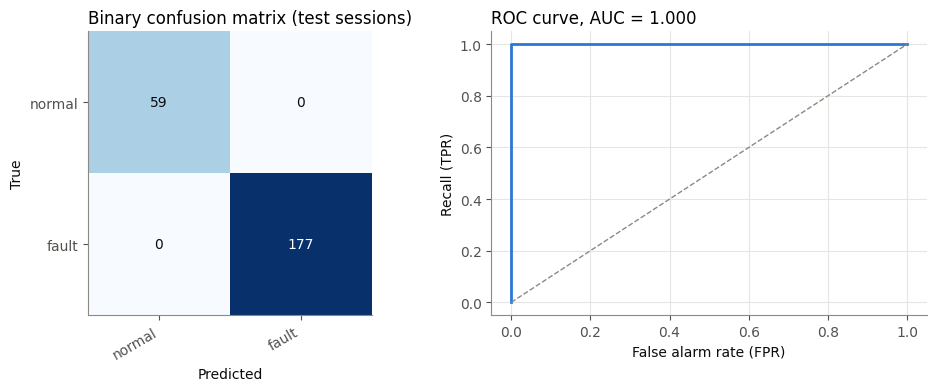

In [8]:
cm = confusion_matrix(y_bin[test_mask], (p_test >= 0.5).astype(int), labels=[0, 1])
fpr, tpr, _ = roc_curve(y_bin[test_mask], p_test)

def plot_cm(ax, cm, names, title):
    ax.imshow(cm, cmap="Blues", vmin=0)
    ax.grid(False)
    ax.set_xticks(range(len(names)), names, rotation=30, ha="right")
    ax.set_yticks(range(len(names)), names)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title, loc="left")
    thresh = cm.max() / 2
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "#0b0b0b")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_cm(axes[0], cm, ["normal", "fault"], "Binary confusion matrix (test sessions)")
axes[1].plot(fpr, tpr, color=BLUE, lw=2)
axes[1].plot([0, 1], [0, 1], color="#8a8984", lw=1, ls="--")
axes[1].set_xlabel("False alarm rate (FPR)"); axes[1].set_ylabel("Recall (TPR)")
axes[1].set_title(f"ROC curve, AUC = {main_metrics['roc_auc']:.3f}", loc="left")
plt.tight_layout(); plt.show()

## 4. Robustness check: 5 session-level rounds

One test session per condition is a small test set, so the result can depend on which session happened to be last. Here **round k tests on session k of every condition** and trains on the other 4 (round 5 is the shared split above). Every session is tested once, and `C` is re-tuned inside each round.

In [9]:
fold_rows, held_probs = [], []
for k in range(5):
    te_k = (train_df.idx == k).to_numpy()
    model, best_C = tuned_fit(X[~te_k], y_bin[~te_k], groups[~te_k], scoring="f1")
    m, _, p_held = binary_metrics(model, te_k)
    held_probs.append(p_held)
    fold_rows.append({"test_session": k + 1, "C": best_C, **m})

folds = pd.DataFrame(fold_rows)
metric_cols = ["accuracy", "precision", "recall", "f1", "false_alarm_rate", "roc_auc", "heldout_recall"]
display(folds.round(3))
cv_summary = folds[metric_cols].agg(["mean", "std"]).T.round(3)
cv_summary

,test_session,C,accuracy,precision,recall,f1,false_alarm_rate,roc_auc,heldout_recall
0,1,1.0,0.949,0.994,0.938,0.965,0.017,0.983,1.0
1,2,10.0,1.000,1.000,1.000,1.000,0.000,1.000,1.0
2,3,10.0,1.000,1.000,1.000,1.000,0.000,1.000,1.0
3,4,1000.0,1.000,1.000,1.000,1.000,0.000,1.000,1.0
4,5,10.0,1.000,1.000,1.000,1.000,0.000,1.000,1.0


,mean,std
accuracy,0.990,0.023
precision,0.999,0.003
recall,0.988,0.028
f1,0.993,0.016
false_alarm_rate,0.003,0.007
roc_auc,0.997,0.007
heldout_recall,1.000,0.000


## 5. Generalization test: the held-out fault

The held-out fault (a light blade rub: ~1 mm of index card touching the blade tips) was never in any training set. A window counts as caught if the model says *fault*.

The rub changed as the card wore: session 1 shows the ~195 Hz blade-pass tone (like blocked airflow), while later sessions mainly add high-frequency (200-500 Hz) buzz (more like loose mount). Section 7 shows which known fault the multiclass model mistakes it for.

In [10]:
print(f"Held-out recall, shared-split model: {main_metrics['heldout_recall']:.3f}")
print(f"Held-out recall over the 5 rounds:   {folds.heldout_recall.mean():.3f} +/- {folds.heldout_recall.std():.3f}")

per_session = (held_df.assign(caught=(p_held_main >= 0.5))
                      .groupby("session").caught.mean().rename("fraction_flagged"))
per_session.round(3)

Held-out recall, shared-split model: 1.000
Held-out recall over the 5 rounds:   1.000 +/- 0.000


session
heldout_20261119_164606    1.0
heldout_20261119_165051    1.0
heldout_20261119_165221    1.0
heldout_20261119_165406    1.0
heldout_20261119_165549    1.0
Name: fraction_flagged, dtype: float64

## 6. Sanity check: how much does fan speed alone explain?

Same algorithm and same shared split, but the only input is the session's mean RPM from its `.json` file. If this alone scores close to the full model, the result is partly about fan speed rather than vibration patterns.

In [11]:
rpm_map = dict(zip(sess_df.session, sess_df.rpm))
X_rpm = train_df.session.map(rpm_map).to_numpy(dtype=float).reshape(-1, 1)
X_rpm_held = held_df.session.map(rpm_map).to_numpy(dtype=float).reshape(-1, 1)

rpm_model = make_model().fit(X_rpm[~test_mask], y_bin[~test_mask])
rpm_pred = rpm_model.predict(X_rpm[test_mask])
pd.DataFrame({
    "vibration features": [main_metrics["f1"], main_metrics["heldout_recall"]],
    "fan RPM only": [f1_score(y_bin[test_mask], rpm_pred), rpm_model.predict(X_rpm_held).mean()],
}, index=["f1", "heldout_recall"]).round(3)

,vibration features,fan RPM only
f1,1.0,0.667
heldout_recall,1.0,0.600


## 7. Extra result: which fault is it? (multiclass)

Same features, shared split and tuning, but the model predicts one of the four training conditions.

In [12]:
multi_model, multi_C = tuned_fit(X[~test_mask], y_multi[~test_mask], groups[~test_mask], scoring="f1_macro")
pred_multi = multi_model.predict(X[test_mask])
held_multi = multi_model.predict(X_held)
multi_metrics = {"C": multi_C,
                 "accuracy": accuracy_score(y_multi[test_mask], pred_multi),
                 "macro_f1": f1_score(y_multi[test_mask], pred_multi, average="macro")}
pd.Series(multi_metrics).round(3).to_frame("multiclass, shared split")

,"multiclass, shared split"
C,0.100
accuracy,0.983
macro_f1,0.983


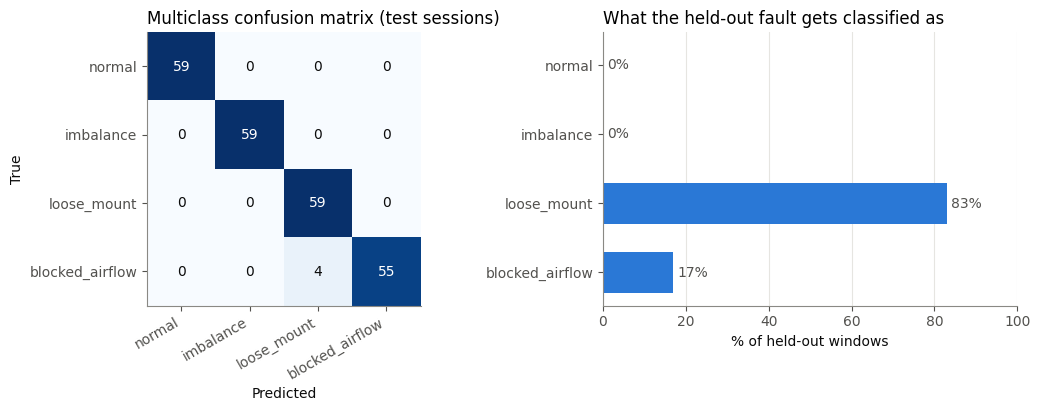

In [13]:
cm_multi = confusion_matrix(y_multi[test_mask], pred_multi, labels=TRAIN_LABELS)
held_share = pd.Series(held_multi).value_counts(normalize=True).reindex(TRAIN_LABELS, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
plot_cm(axes[0], cm_multi, TRAIN_LABELS, "Multiclass confusion matrix (test sessions)")
axes[1].barh(TRAIN_LABELS[::-1], held_share[TRAIN_LABELS[::-1]] * 100, color=BLUE, height=0.6)
axes[1].set_xlabel("% of held-out windows"); axes[1].set_xlim(0, 100)
axes[1].set_title("What the held-out fault gets classified as", loc="left")
axes[1].grid(axis="y", visible=False)
for i, v in enumerate(held_share[TRAIN_LABELS[::-1]] * 100):
    axes[1].text(v + 1, i, f"{v:.0f}%", va="center", color="#52514e")
plt.tight_layout(); plt.show()

## 8. ESP32 export

The exported model is the **shared-split binary model** from section 3 (trained on sessions 1-4), so the on-device test on session 5 is a fair test. On the ESP32 the prediction is:

```
z_i = (feature_i - MEAN[i]) / SCALE[i]
score = INTERCEPT + sum(COEF[i] * z_i)
p_fault = 1 / (1 + exp(-score))      // fault if p_fault >= 0.5  (i.e. score >= 0)
```

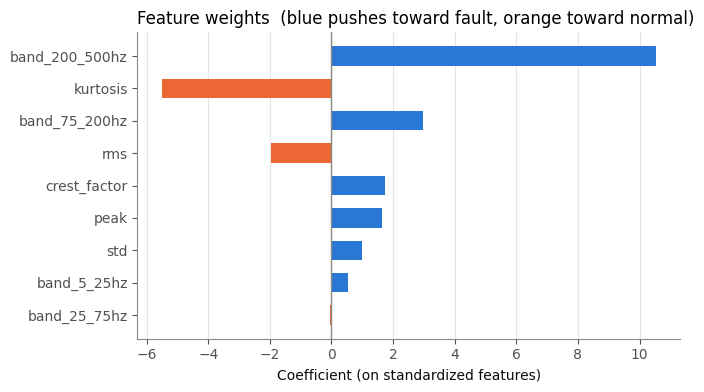

In [14]:
scaler = main_model.named_steps["standardscaler"]
clf    = main_model.named_steps["logisticregression"]

coef = pd.Series(clf.coef_[0], index=FEATURE_NAMES).sort_values(key=np.abs)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(coef.index, coef.values, color=[BLUE if v > 0 else ORANGE for v in coef.values], height=0.6)
ax.axvline(0, color="#8a8984", lw=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Coefficient (on standardized features)")
ax.set_title("Feature weights  (blue pushes toward fault, orange toward normal)", loc="left")
plt.tight_layout(); plt.show()

In [15]:
# Check: plain float32 math (what the ESP32 will do) gives the same predictions as scikit-learn
MEAN  = scaler.mean_.astype(np.float32)
SCALE = scaler.scale_.astype(np.float32)
COEF  = clf.coef_[0].astype(np.float32)
INTERCEPT = np.float32(clf.intercept_[0])

def c_style_predict(x):
    z = (x.astype(np.float32) - MEAN) / SCALE
    score = INTERCEPT + np.sum(COEF * z, axis=-1)
    return 1 / (1 + np.exp(-score))

X_all = np.vstack([X, X_held])
p_sk = main_model.predict_proba(X_all)[:, 1]
p_c  = c_style_predict(X_all)
print(f"Max probability difference: {np.max(np.abs(p_sk - p_c)):.2e}")
print(f"Prediction agreement:       {np.mean((p_sk >= 0.5) == (p_c >= 0.5)) * 100:.2f}%")

Max probability difference: 1.04e-05
Prediction agreement:       100.00%


In [16]:
def c_array(name, values):
    body = ",\n  ".join(", ".join(f"{v:.8e}f" for v in values[i:i + 3]) for i in range(0, len(values), 3))
    return f"static const float {name}[N_FEATURES] = {{\n  {body}\n}};\n"

header = f'''// Logistic regression fan-fault detector (normal = 0, fault = 1)
// Generated by logistic_regression.ipynb (shared split, C = {main_C}).
// Features come from features.py. Input: 1000 samples at 1 kHz of the acceleration
// magnitude sqrt(ax^2 + ay^2 + az^2) in m/s^2 (raw counts * 9.80665 / {COUNTS_PER_G:.0f}, +/-8 g range).
// Feature order MUST be:
//   {", ".join(FEATURE_NAMES)}
// kurtosis = excess kurtosis (m4 / m2^2 - 3); crest_factor = peak / rms;
// band_* = mean over FFT bins in [lo, hi) Hz of (2 * |FFT(x - mean)| / N)^2.
#pragma once
#include <math.h>

#define N_FEATURES {len(FEATURE_NAMES)}

{c_array("LR_MEAN", MEAN)}
{c_array("LR_SCALE", SCALE)}
{c_array("LR_COEF", COEF)}
static const float LR_INTERCEPT = {INTERCEPT:.8e}f;

// Returns the probability that the window is a fault.
static inline float lr_predict_proba(const float *x) {{
  float s = LR_INTERCEPT;
  for (int i = 0; i < N_FEATURES; i++) s += LR_COEF[i] * (x[i] - LR_MEAN[i]) / LR_SCALE[i];
  return 1.0f / (1.0f + expf(-s));
}}
'''
(MODEL_DIR / "logreg_model.h").write_text(header)
param_bytes = 4 * (3 * len(FEATURE_NAMES) + 1)
print(f"Wrote ../model/logreg_model.h  ({param_bytes} bytes of model parameters)")

# The deployed copy lives in the firmware folder; check it is the same model
deployed = (ROOT / "firmware" / "fault_detector" / "logreg_model.h").read_text()
print("Matches the header deployed in firmware/fault_detector:", deployed.strip() == header.strip())

Wrote ../model/logreg_model.h  (112 bytes of model parameters)
Matches the header deployed in firmware/fault_detector: True


## 9. Results summary (for the comparison table)

Main columns are from the shared split; `*_cv_mean` columns are the 5-round averages from section 4.

In [17]:
results = pd.DataFrame([{
    "model": "Logistic regression",
    **{k: main_metrics[k] for k in ["precision", "recall", "f1", "false_alarm_rate", "roc_auc", "heldout_recall"]},
    "f1_cv_mean": folds.f1.mean(),
    "heldout_recall_cv_mean": folds.heldout_recall.mean(),
    "multiclass_macro_f1": multi_metrics["macro_f1"],
    "param_bytes": param_bytes,
    "inference_us_esp32": "10-18",   # measured: verify mode ~10 us, live mode ~18 us
    "feature_ms_esp32": 42.8,
}]).round(3)
results.to_csv(MODEL_DIR / "results_logistic_regression.csv", index=False)
results.T

,0
model,Logistic regression
precision,1.0
recall,1.0
f1,1.0
false_alarm_rate,0.0
roc_auc,1.0
heldout_recall,1.0
f1_cv_mean,0.993
heldout_recall_cv_mean,1.0
multiclass_macro_f1,0.983


## 10. On the ESP32: does the C version match Python?

The detector sketch (`firmware/fault_detector`) computes the same 9 features in C and runs the exported header. In verify mode the PC sends recorded windows to the board and compares the board's features and prediction with Python (`scripts/esp32_test.py verify`). These are the saved results of that run on the real board.

In [18]:
ver = pd.read_csv(RESULTS_DIR / "esp32_verify_results.csv")
print(f"Windows tested on the board: {len(ver)}")
print(f"ESP32 = Python predictions:  {(ver.esp_pred == ver.py_pred).mean() * 100:.2f}%")
print(f"Largest probability diff:    {(ver.esp_p - ver.py_p).abs().max():.1e}")
zcols = [c for c in ver.columns if c.startswith("zerr_")]
print(f"Largest feature error:       {ver[zcols].max().max():.1e} standard deviations")
print(f"Feature extraction:          {ver.feat_us.mean() / 1000:.2f} ms per window")
print(f"Inference:                   {ver.infer_us.mean():.1f} us per window (max {ver.infer_us.max()} us)")
ver.groupby("label").apply(lambda d: pd.Series({"windows": len(d), "accuracy_%": (d.esp_pred == d.truth).mean() * 100}),
                           include_groups=False)

Windows tested on the board: 531
ESP32 = Python predictions:  100.00%
Largest probability diff:    5.6e-05
Largest feature error:       1.6e-03 standard deviations
Feature extraction:          42.80 ms per window
Inference:                   9.6 us per window (max 38 us)


,windows,accuracy_%
label,,
blocked_airflow,59.0,100.0
heldout,295.0,100.0
imbalance,59.0,100.0
loose_mount,59.0,100.0
normal,59.0,100.0


## 11. Live tests on the running fan

Each run classified 1-s windows live on the ESP32 (`scripts/esp32_test.py live --save ...`); an alert needs 3 fault windows in a row. Runs named `*_midrun` / `*_midway` started healthy and had the fault added during the run.

In [19]:
LIVE_DIR = RESULTS_DIR / "live_runs"
live = pd.DataFrame([json.loads(p.read_text()) for p in sorted(LIVE_DIR.glob("*_summary.json"))])
live[["started", "condition", "notes", "windows", "percent_flagged_fault", "percent_correct", "alerts",
      "mean_rpm", "inference_us_mean"]].set_index("started")

,condition,notes,windows,percent_flagged_fault,percent_correct,alerts,mean_rpm,inference_us_mean
started,,,,,,,,
2026-11-19T19:01:48,blocked_airflow_midrun,"card placed flat at ~10 s, not touching blades",39,71.79,NaN,1,1672.0,17.97
2026-11-19T18:24:37,fan_obstruction_midway,note card clips fan around ~20 s,29,27.59,NaN,1,1704.9,18.38
2026-11-19T18:30:27,imbalance,twist tie on fan blade,29,86.21,86.21,1,1674.0,18.41
2026-11-19T18:41:50,imbalance,twist tie on fan blade part 2,28,100.00,100.00,1,1674.3,18.18
2026-11-19T18:50:31,loose_mount,,28,0.00,0.00,0,1677.4,17.96
2026-11-19T18:55:01,loose_mount,bottom left tape fixture removed,29,96.55,96.55,1,1684.9,18.14
2026-11-19T18:58:35,loose_mount_midrun,bottom left tape removed at ~10 s,39,58.97,NaN,1,1708.3,18.15
2026-11-19T17:55:26,normal,after re-taping all corners,29,0.00,100.00,0,1694.0,18.07


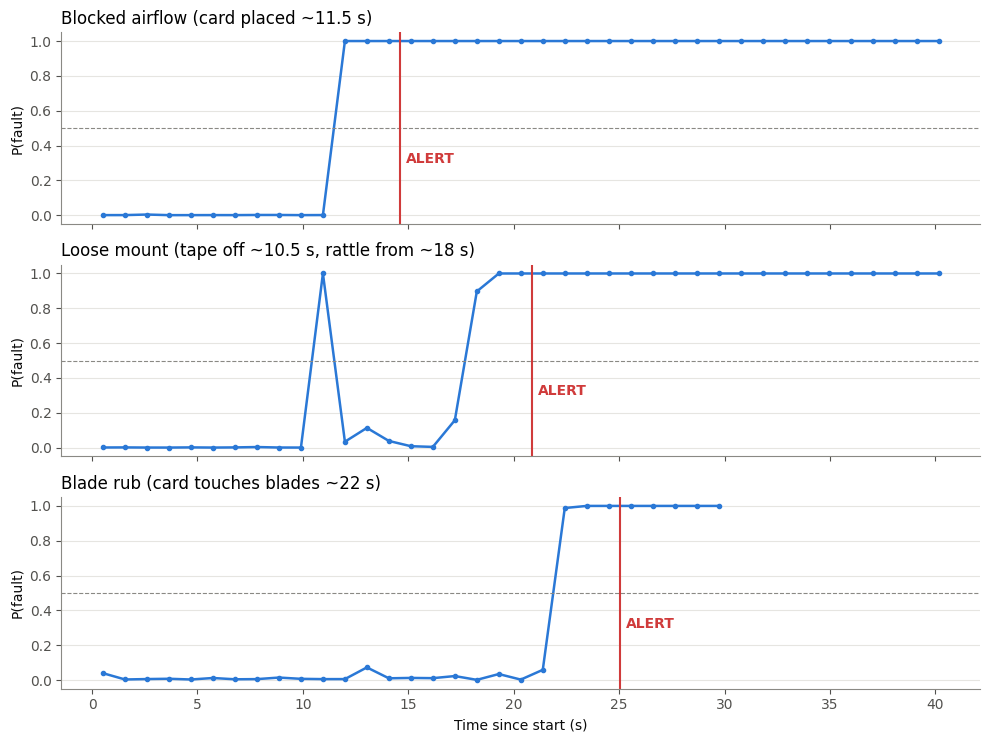

In [20]:
WINDOW_S = 1.0 + 0.0428      # 1 s of sampling + 42.8 ms of feature extraction per window
runs = [("Blocked airflow (card placed ~11.5 s)", "live_blocked_airflow_midrun_*.csv"),
        ("Loose mount (tape off ~10.5 s, rattle from ~18 s)", "live_loose_mount_midrun_*.csv"),
        ("Blade rub (card touches blades ~22 s)", "live_fan_obstruction_midway_*.csv")]
fig, axes = plt.subplots(len(runs), 1, figsize=(10, 7.5), sharex=True)
for ax, (title, pattern) in zip(axes, runs):
    f = sorted(p for p in LIVE_DIR.glob(pattern) if "_vs_recorded_normal" not in p.name)[-1]
    d = pd.read_csv(f)
    t = (d.window + 0.5) * WINDOW_S
    ax.plot(t, d.p_fault, color=BLUE, lw=1.8, marker="o", ms=3)
    ax.axhline(0.5, color="#8a8984", lw=0.8, ls="--")
    for _, r in d[d.event == "ALERT"].iterrows():
        ax.axvline((r.window + 1) * WINDOW_S, color="#d03b3b", lw=1.5)
        ax.text((r.window + 1) * WINDOW_S + 0.3, 0.3, "ALERT", color="#d03b3b", fontweight="bold")
    ax.set_ylim(-0.05, 1.05); ax.set_ylabel("P(fault)"); ax.set_title(title, loc="left")
    ax.grid(axis="x", visible=False)
axes[-1].set_xlabel("Time since start (s)")
plt.tight_layout(); plt.show()

## 12. Lab log: what happened and why

**November 16: first data set (later replaced).** Fan at full speed, sensor at ±2 g. A classifier given only the fan speed separated normal from fault *perfectly*: normal sessions ran at ~950 RPM and every fault at 690–800 RPM. The cause was a **faulty ground** limiting the fan. Lesson: always log RPM.

**November 19: re-recorded everything.**
- Added an `rpm` column to every CSV row and min/max RPM to the JSON (`record_session.py`); fixed the ground, after which the fan ran at ~2,000 RPM.
- The first imbalance session (a nickel on a blade) **clipped** the ±2 g sensor (26,059 maxed-out readings). Switched to **±8 g** (4096 counts/g), set the fan to **80% duty (204/255, ~1,690 RPM, 28 Hz spin)**, and added a clipped-reading count to the logger.
- Conditions: imbalance = 4 cm twist tie on one blade (28 Hz peak ~60 mg vs. ~2 mg normal); loose mount = bottom-left corner untaped (200–500 Hz rattle, 1.46e-5 vs. 0.61e-5 normal); blocked airflow = index card over half the intake (blade-pass tone at ~195 Hz, 7 blades); held-out = ~1 mm of index card rubbing the blade tips (changed from "flicking" to "brushing" as the card wore).
- Every condition ran within ~1% of the same fan speed: fan speed alone now only reaches F1 0.667.

**Model.** The shared `features.py` still used the ±2 g scale; this notebook uses 9.80665/4096 (and the team was told). With the corrected scale the binary model chose C = 10, and its weights lean on the 200–500 Hz band; the 25–75 Hz band holding imbalance's 28 Hz peak gets almost no weight. A log transform of the band energies would probably fix that; **kept the model unchanged** so the paper, slides and board all match.

**ESP32.** C features checked against Python on all 1,476 windows on the PC, then 531/531 windows on the board. Two serial problems fixed on the way: a byte occasionally lost at 921,600 baud (receive FIFO threshold lowered to 32, checksum + resend) and reply lines held in the transmit buffer (flush after every line).

**Live tests.**
- A normal test first **failed** (every window "fault"): the features matched the recorded loose mount. A corner had come loose while re-seating the fan; after re-taping all four corners it passed 29/29.
- A weaker twist tie (~60% of the recorded vibration) was caught in only 86% of windows (the side-effect weighting).
- A loose corner that sat still produced no extra vibration and was never flagged; removing the tape fixture made it rattle and it was caught 28/29.
- Faults added mid-run: no false alarms before, alert 3.1 s after the fault appeared every time (the minimum for 3 windows in a row). In the blocked-airflow run the card fluttered or touched the blades, so its vibration was stronger than the recordings.

**Where everything is** (in `fan_fault_experiment/`): `data/` recordings · `firmware/` logger and detector sketches · `scripts/` recording, ESP32 test and figure scripts · `model/` exported header and results · `results/` ESP32 verification and live runs · `figures/` slide and paper figures · `paper/` IEEE draft · `photos/` setup photos · `model_benchmark/` the team's shared benchmark kit · `archive/` zipped copy of the data.